In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

file_rotterdamXLS =  r"\Users\svenv\OneDrive\Documenten\2DMM30_stochastics_simulation\Simulation_assignment\rotterdam_dataset_02.xlsx"
df_rotterdam = pd.read_excel(file_rotterdamXLS)
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


In [43]:
df_weight = df_rotterdam[['Vessel_Type', 'Cargo_tons']].copy()
df_weight_grouped = df_weight.groupby('Vessel_Type')
df_vessel_means = df_weight_grouped['Cargo_tons'].describe()
df_vessel_means

,count,mean,std,min,25%,50%,75%,max
Vessel_Type,,,,,,,,
Bulk,5133.0,39785.565556,16193.349694,4911.0,27896.0,37853.0,48969.0,144480.0
Container,10420.0,15765.674952,5635.666662,4125.0,11720.0,14809.5,18851.5,56006.0
Tanker,2317.0,51268.459215,15322.487237,19740.0,40182.0,49016.0,60381.0,128221.0


In [44]:
bulk_mean = df_vessel_means['mean'].iloc[0]
bulk_std = df_vessel_means['std'].iloc[0]

container_mean = df_vessel_means['mean'].iloc[1]
container_std = df_vessel_means['std'].iloc[1]

tanker_mean = df_vessel_means['mean'].iloc[2]
tanker_std = df_vessel_means['std'].iloc[2]

In [45]:
def lognormal_moments(mean, variance):
    lognormal_variance = np.log(1 + variance / mean**2)
    lognormal_mean = np.log(mean) - lognormal_variance / 2
    return lognormal_mean, np.sqrt(lognormal_variance)

mu_bulk, sigma_bulk = lognormal_moments(bulk_mean, bulk_std**2)
mu_container, sigma_container = lognormal_moments(container_mean, container_std**2)
mu_tanker, sigma_tanker = lognormal_moments(tanker_mean, tanker_std**2)

In [46]:
logNormDistEst_bulk = stats.lognorm(s=sigma_bulk, scale=np.exp(mu_bulk))
logNormDistEst_container = stats.lognorm(s=sigma_container, scale=np.exp(mu_container))
logNormDistEst_tanker = stats.lognorm(s=sigma_tanker, scale=np.exp(mu_tanker))

In [47]:
df_times = df_rotterdam[['Arrival_Date', 'Vessel_Type']].copy()
df_times = df_times.sort_values(by='Arrival_Date').reset_index(drop=True)
df_times.head()

,Arrival_Date,Vessel_Type
0,2022-01-01 00:04:00,Bulk
1,2022-01-01 00:55:00,Tanker
2,2022-01-01 01:13:00,Tanker
3,2022-01-01 02:08:00,Tanker
4,2022-01-01 02:59:00,Container


In [48]:
df_times_bulk = df_times[df_times['Vessel_Type'] == 'Bulk'].copy()
df_times_bulk['Time_diff'] = df_times_bulk['Arrival_Date'].diff()

df_times_tanker = df_times[df_times['Vessel_Type'] == 'Tanker'].copy()
df_times_tanker['Time_diff'] = df_times_tanker['Arrival_Date'].diff()

df_times_container = df_times[df_times['Vessel_Type'] == 'Container'].copy()
df_times_container['Time_diff'] = df_times_container['Arrival_Date'].diff()

In [49]:
iat_bulk = df_times_bulk['Time_diff'].dropna().dt.total_seconds() / 86400
lam_bulk = 1 / np.mean(iat_bulk)

iat_tanker = df_times_tanker['Time_diff'].dropna().dt.total_seconds() / 86400
lam_tanker = 1 / np.mean(iat_tanker)

iat_container = df_times_container['Time_diff'].dropna().dt.total_seconds() / 86400
lam_container = 1 / np.mean(iat_container)

print(lam_bulk)
print(lam_tanker)
print(lam_container)

4.683989422791703
2.113845873011044
9.508133971291867


In [50]:
def simPoissonProcess(lam, t, cargoDist):
    Nt = 0 # counter
    interArrivalTimeDist = stats.expon(scale = 1 / lam)
    time = interArrivalTimeDist.rvs()
    total_weight = 0
    while time < t:
        Nt += 1
        time += interArrivalTimeDist.rvs()
        total_weight += cargoDist.rvs()
    return Nt, total_weight

In [51]:
def simScenario(lamB, lamC, lamT, distB, distC, distT, nrRuns, t):
    N_B = np.zeros(nrRuns) 
    S_B = np.zeros(nrRuns)
    N_C = np.zeros(nrRuns)
    S_C = np.zeros(nrRuns)
    N_T = np.zeros(nrRuns)
    S_T = np.zeros(nrRuns)
    for i in range(nrRuns):
        N_B[i], S_B[i] = simPoissonProcess(lamB, t, distB)
        N_C[i], S_C[i] = simPoissonProcess(lamC, t, distC)
        N_T[i], S_T[i] = simPoissonProcess(lamT, t, distT)
    return N_B, N_C, N_T, S_B, S_C, S_T

In [52]:
def logNormDist(mean, std):
    mu, sigma = lognormal_moments(mean, std**2)
    return stats.lognorm(s=sigma, scale=np.exp(mu))

In [53]:
def simExceed(lamB, lamC, lamT, distB, distC, distT, nrRuns, capacity):
    exceed = np.zeros(nrRuns)
    for i in range(nrRuns):
        exceed[i] = simPoissonProcess(lamB, 1, distB)[1] + simPoissonProcess(lamC, 1, distC)[1] + simPoissonProcess(lamT, 1, distT)[1] > capacity
    return exceed

In [54]:
years = 5
nrRuns = 200            # simulated years per step (for N and S)
nrRunsExceed = 5000     # simulated days per step (for the exceedance probability)
t = 365
capacity = 650000


# Simulation for 'Growth in trade volume'

meanN_g = np.zeros(years); meanS_g = np.zeros(years); q95N_g = np.zeros(years); q95S_g = np.zeros(years)
stdN_g = np.zeros(years); stdS_g = np.zeros(years)
pExceed_g = np.zeros(years); ciExceed_g = np.zeros((years, 2))

for k in range(1, years + 1):
    g_k = 1.03**k # Assume a 3% per year increase
    N_B, N_C, N_T, S_B, S_C, S_T = simScenario(lam_bulk * g_k, lam_container * g_k, lam_tanker * g_k, logNormDistEst_bulk, logNormDistEst_container, logNormDistEst_tanker, nrRuns, t)
    meanN_g[k-1] = (N_B + N_C + N_T).mean()
    meanS_g[k-1] = (S_B + S_C + S_T).mean()
    stdN_g[k-1] = (N_B + N_C + N_T).std()
    stdS_g[k-1] = (S_B + S_C + S_T).std()
    q95N_g[k-1] = np.quantile(N_B + N_C + N_T, 0.95)
    q95S_g[k-1] = np.quantile(S_B + S_C + S_T, 0.95)

    exceed = simExceed(lam_bulk * g_k, lam_container * g_k, lam_tanker * g_k, logNormDistEst_bulk, logNormDistEst_container, logNormDistEst_tanker, nrRunsExceed, capacity)
    pExceed_g[k-1] = np.mean(exceed)
    halfWidth = 1.96 * np.std(exceed) / np.sqrt(nrRunsExceed)
    ciExceed_g[k-1] = (pExceed_g[k-1] - halfWidth, pExceed_g[k-1] + halfWidth)

    print(k, round(g_k, 3), meanN_g[k-1], meanS_g[k-1], q95N_g[k-1], q95S_g[k-1], stdN_g[k-1], stdS_g[k-1], pExceed_g[k-1], ciExceed_g[k-1])

1 1.03 6132.165 167337083.09744152 6260.15 171539505.66914976 80.1183360723374 2480104.2562156185 0.0874 [0.07957171 0.09522829]
2 1.061 6312.465 172056426.29282573 6439.1 176354826.4922905 81.92538541258136 2589340.755544677 0.103 [0.09457469 0.11142531]
3 1.093 6513.885 177566100.1060295 6660.05 182264373.46671 84.65159050484522 2757748.2309346343 0.1144 [0.10557727 0.12322273]
4 1.126 6698.09 182502821.28676727 6824.05 186995990.88797924 81.78552378018985 2509302.033609803 0.1404 [0.13077052 0.15002948]
5 1.159 6895.1 188171816.44128883 7037.45 192525851.17626745 86.44235073157138 2668491.4618599494 0.1762 [0.16563949 0.18676051]


In [55]:
# Simulation for 'Larger vessels'

years = 5
nrRuns = 200            # simulated years per step (for N and S)
nrRunsExceed = 5000     # simulated days per step (for the exceedance probability)
t = 365
capacity = 650000


meanN_l = np.zeros(years); meanS_l = np.zeros(years); q95N_l = np.zeros(years); q95S_l = np.zeros(years)
stdN_l = np.zeros(years); stdS_l = np.zeros(years)
pExceed_l = np.zeros(years); ciExceed_l = np.zeros((years, 2))

for k in range(1, years + 1):
    c_k = 1.03**k # Assume a 3% increase per year again
    distB = logNormDist(bulk_mean * c_k, bulk_std * c_k)
    distC = logNormDist(container_mean * c_k, container_std * c_k)
    distT = logNormDist(tanker_mean * c_k, tanker_std * c_k)

    N_B, N_C, N_T, S_B, S_C, S_T = simScenario(lam_bulk, lam_container, lam_tanker, distB, distC, distT, nrRuns, t)
    meanN_l[k-1] = (N_B + N_C + N_T).mean()
    meanS_l[k-1] = (S_B + S_C + S_T).mean()
    stdN_l[k-1] = (N_B + N_C + N_T).std()
    stdS_l[k-1] = (S_B + S_C + S_T).std()
    q95N_l[k-1] = np.quantile(N_B + N_C + N_T, 0.95)
    q95S_l[k-1] = np.quantile(S_B + S_C + S_T, 0.95)

    exceed = simExceed(lam_bulk, lam_container, lam_tanker, distB, distC, distT, nrRunsExceed, capacity)
    pExceed_l[k-1] = np.mean(exceed)
    halfWidth = 1.96 * np.std(exceed) / np.sqrt(nrRunsExceed)
    ciExceed_l[k-1] = (pExceed_l[k-1] - halfWidth, pExceed_l[k-1] + halfWidth)

    print(k, round(c_k, 3), meanN_l[k-1], meanS_l[k-1], q95N_l[k-1], q95S_l[k-1], stdN_l[k-1], stdS_l[k-1], pExceed_l[k-1], ciExceed_l[k-1])

1 1.03 5953.885 167316605.9650337 6080.2 171515180.5730937 81.7880906672848 2667232.3384971297 0.0898 [0.08187539 0.09772461]
2 1.061 5954.845 172192757.89161742 6080.2 177289346.2370322 80.76503559709485 2858368.900775352 0.1086 [0.09997573 0.11722427]
3 1.093 5944.775 177270368.03532258 6066.25 181733082.99737814 72.15514101573082 2611469.3466160046 0.1364 [0.12688663 0.14591337]
4 1.126 5950.245 182554305.71685284 6081.15 187742170.0168708 81.31983137587042 3043651.2827911624 0.1578 [0.1476951 0.1679049]
5 1.159 5953.98 188205483.4077663 6067.25 193018721.06809592 75.48410163736467 2872410.5060341926 0.1892 [0.17834353 0.20005647]


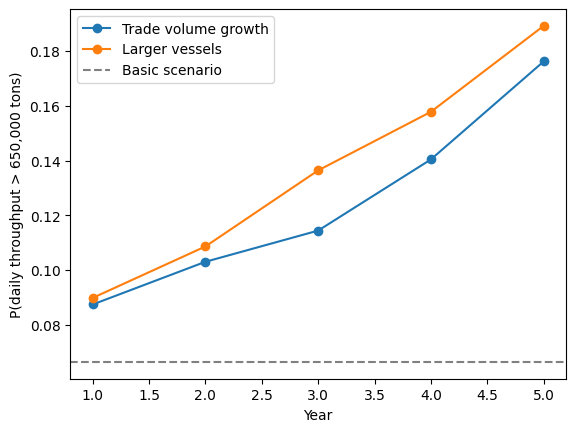

In [56]:
plt.figure()
plt.plot(range(1, years + 1), pExceed_g, marker='o', label='Trade volume growth')
plt.plot(range(1, years + 1), pExceed_l, marker='o', label='Larger vessels')
plt.axhline(0.0664, color='gray', linestyle='--', label='Basic scenario')
plt.xlabel('Year')
plt.ylabel('P(daily throughput > 650,000 tons)')
plt.legend()
plt.show()

In [57]:
def simStrike(days, strikeStart, strikeLength, efficiency, capacity):
    backlog = 0
    peakBacklog = 0
    daysToClear = np.nan
    for day in range(days):
        arrived = simPoissonProcess(lam_bulk, 1, logNormDistEst_bulk)[1] + simPoissonProcess(lam_container, 1, logNormDistEst_container)[1] + simPoissonProcess(lam_tanker, 1, logNormDistEst_tanker)[1]
        if day >= strikeStart and day < strikeStart + strikeLength:
            cap = capacity * efficiency
        else:
            cap = capacity
        backlog = max(0, backlog + arrived - cap)
        peakBacklog = max(peakBacklog, backlog)
        if day >= strikeStart + strikeLength and backlog == 0 and np.isnan(daysToClear):
            daysToClear = day - (strikeStart + strikeLength) + 1
    return peakBacklog, daysToClear

nrRuns = 2000
peak = np.zeros(nrRuns)
clear = np.zeros(nrRuns)
for i in range(nrRuns):
    peak[i], clear[i] = simStrike(60, 0, 7, 0.5, 650000)   # 60-day window, 7-day strike at 50% capacity

print(np.mean(peak), np.quantile(peak, 0.95))
print(np.nanmean(clear), np.nanquantile(clear, 0.95)) # Number of days the port needs to catch up with missed arrivals due to strike

874482.7728258738 1456081.324185088
4.8535 9.0
